# Lab Assignment 12: End-to-End NLP Application — Fact-Checking Dialogue System

**Course:** Applied NLP  
**Submission:** Upload `Lab_12.ipynb` to Canvas with all cells run and outputs visible.

---

## Overview

This lab brings together the core skills from across the course into a single end-to-end NLP application. You will build, evaluate, diagnose, and improve a **retrieval-based fact-checking dialogue system** — a bot that responds to user queries about common news misinformation topics by retrieving the most relevant factual correction from a curated response bank.

The application is grounded in the fake news corpus introduced in the Module 13 companion notebook. You have already seen the classification pipeline, named entity analysis, and summarization components applied to this corpus. Here you design the complete system: preprocessing, retrieval, evaluation, failure diagnosis, and a reasoned improvement cycle.

The response bank is fixed and provided — all 30 entries cover misinformation topics drawn from the corpus's entity distribution. This lets you focus on the engineering and evaluation decisions rather than content creation, and makes your results directly comparable across the class.

---

## Learning Objectives

1. Design and implement an end-to-end NLP application integrating preprocessing, modeling, and output interpretation
2. Evaluate a retrieval-based dialogue system using appropriate metrics and diagnose systematic errors
3. Compare extractive and abstractive summarization approaches and justify approach selection given task constraints
4. Prototype and evaluate a retrieval-based dialogue component against defined criteria for response relevance and coherence

---

## Grading

| Component | Points | Method |
|---|---|---|
| Part 1 — Corpus understanding and summarization | 14 | Autograded (8) + Manual (6) |
| Part 2 — System design | 10 | Manual (10) |
| Part 3 — Retrieval system implementation | 20 | Autograded (14) + Manual (6) |
| Part 4 — Evaluation | 24 | Autograded (12) + Manual (12) |
| Part 5 — Failure diagnosis and iteration | 16 | Autograded (6) + Manual (10) |
| Part 6 — Reflection | 10 | Manual (10) |
| **Total** | **100** | Autograded (40) + Manual (60) |

### Manual grading rubric — code quality is assessed within each part's manual component.

All written responses require specific, evidence-grounded claims with precise terminology.

---

## Setup

In [1]:
# Setup — run this cell first every session.

import subprocess, sys

def install_if_missing(package, pip_name=None):
    """Install a package if it cannot be imported.

    Args:
        package  (str): Importable module name.
        pip_name (str): pip install name if different.

    Returns:
        None. Installs the package with pip only when the import fails.
    """
    try:
        __import__(package)
    except ImportError:
        subprocess.check_call([sys.executable, '-m', 'pip',
                               'install', '-q', pip_name or package])

for pkg, pip in [
    ('spacy',       None),
    ('rouge_score', None),
    ('nltk',        None),
    ('sklearn',     'scikit-learn'),
    ('numpy',       None),
    ('matplotlib',  None),
    ('pandas',      None),
    ('torch',       None),   # added: BART summarizer in 1.3
    ('transformers', None),  # added: BART summarizer in 1.3
]:
    install_if_missing(pkg, pip)

import spacy
try:
    spacy.load('en_core_web_sm')
except OSError:
    subprocess.check_call([sys.executable, '-m', 'spacy',
                           'download', 'en_core_web_sm'])

import nltk
for pkg in ['punkt', 'punkt_tab', 'stopwords']:
    nltk.download(pkg, quiet=True)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re
from collections import Counter

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

print('Setup complete.')

Setup complete.


---

## Part 1 — Corpus Understanding and Summarization (14 points)

### 1.1 — Load data

Upload `News_combined.csv` to your Colab working directory before running this cell.

In [2]:
# [DO NOT MODIFY] — data loading

data = pd.read_csv('News_combined.csv')
print(f'Shape   : {data.shape}')
print(f'Columns : {list(data.columns)}')
vc = data['class'].value_counts()
print(f'Real (1): {vc[1]:,}   Fake (0): {vc[0]:,}')

Shape   : (44267, 5)
Columns : ['title', 'text', 'subject', 'date', 'class']
Real (1): 21,416   Fake (0): 22,851


### 1.2 — NER-based topic identification

The cell below runs spaCy NER on a sample of 500 fake news articles and prints the top entity distribution. You will use this to understand what topics the response bank covers and to answer the reflection below.

In [3]:
# [DO NOT MODIFY] — NER topic analysis on fake news articles

import spacy
nlp = spacy.load('en_core_web_sm')

fake_sample = data[data['class'] == 0].sample(500, random_state=42)

entity_counts = Counter()
for text in fake_sample['text'].fillna('').values:
    doc = nlp(text[:1000])   # cap at 1000 chars for speed
    for ent in doc.ents:
        if ent.label_ in ('PERSON', 'ORG', 'GPE', 'EVENT', 'NORP'):
            entity_counts[ent.text.lower()] += 1

print("Top 25 named entities in fake news sample (PERSON/ORG/GPE/EVENT/NORP):")
for ent, count in entity_counts.most_common(25):
    print(f"  {ent:<30} {count:>4}")

Top 25 named entities in fake news sample (PERSON/ORG/GPE/EVENT/NORP):
  trump                           470
  donald trump                    199
  obama                           120
  america                          86
  hillary clinton                  80
  republican                       64
  republicans                      54
  us                               54
  american                         51
  cnn                              50
  hillary                          50
  muslim                           47
  americans                        46
  clinton                          45
  u.s.                             43
  doesn                            40
  fbi                              39
  congress                         38
  the united states                35
  twitter                          35
  the white house                  33
  barack obama                     32
  russia                           32
  democrats                        30
  muslims        

### 1.3 — Extractive vs. abstractive summarization

Implement the two summarization functions below and apply them to the same article. This directly exercises the extractive vs. abstractive comparison in the lab's MLOs.

In [4]:
import torch
from nltk.tokenize import sent_tokenize
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

BART_MODEL_NAME = 'facebook/bart-large-cnn'
_BART_CACHE = {}
# A lowercase letter or digit, then . ! or ? (plus an optional quote), glued to a capital
_MISSING_SPACE = re.compile(r'([a-z0-9][.!?]["\']?)([A-Z])')


def textrank_summarize(text, n_sentences=3):
    """Produce an extractive summary using TextRank similarity scoring.

    Steps:
        0. Restore missing spaces after sentence-final punctuation
           (common in this corpus), so sentences are not merged.
        1. Sentence tokenize the text.
        2. TF-IDF vectorize the sentences.
        3. Build a cosine-similarity adjacency matrix between sentences.
        4. Score each sentence by its mean similarity to all others.
        5. Return the top n_sentences in original document order.

    Args:
        text        (str): Input article text.
        n_sentences (int): Number of sentences to extract.

    Returns:
        str: Extracted summary — sentences joined by a space.
             Returns the full text if fewer than n_sentences sentences exist.
    """
    # This corpus often drops the space after a full stop ("the last.Thank"),
    # which makes sent_tokenize merge sentences; restore it first.
    text = _MISSING_SPACE.sub(r'\1 \2', str(text))
    sentences = [s.strip() for s in sent_tokenize(text) if s.strip()]
    if len(sentences) <= n_sentences:
        return ' '.join(sentences)

    try:
        sentence_vectors = TfidfVectorizer(stop_words='english').fit_transform(sentences)
    except ValueError:            # every sentence is stop words only
        return ' '.join(sentences[:n_sentences])

    similarity = cosine_similarity(sentence_vectors)
    np.fill_diagonal(similarity, 0.0)            # a sentence is not its own neighbour
    scores = similarity.sum(axis=1) / (len(sentences) - 1)   # mean similarity to all others

    top_idx = sorted(np.argsort(-scores, kind='stable')[:n_sentences])
    return ' '.join(sentences[i] for i in top_idx)


def _load_bart():
    """Load the BART summarizer once and cache it for later calls.

    The `summarization` pipeline task was removed in transformers 5.0, so the
    tokenizer and model are loaded directly (the approach used in the Module 13
    companion notebook). Runs on a GPU when one is available, otherwise CPU.

    Returns:
        tuple: (tokenizer, model, device) for 'facebook/bart-large-cnn'.
    """
    if 'model' not in _BART_CACHE:
        device = 'cuda' if torch.cuda.is_available() else 'cpu'
        tokenizer = AutoTokenizer.from_pretrained(BART_MODEL_NAME)
        model = AutoModelForSeq2SeqLM.from_pretrained(BART_MODEL_NAME).to(device).eval()
        _BART_CACHE.update(tokenizer=tokenizer, model=model, device=device)
    return _BART_CACHE['tokenizer'], _BART_CACHE['model'], _BART_CACHE['device']


def get_abstractive_summary(text, max_length=80, min_length=30):
    """Generate an abstractive summary using a pretrained BART model.

    Uses 'facebook/bart-large-cnn' through AutoModelForSeq2SeqLM.generate
    (the `summarization` pipeline API no longer exists in transformers 5).
    Truncates input to 1024 tokens to fit the model's context window.

    Args:
        text       (str): Input article text.
        max_length (int): Maximum tokens in the generated summary.
        min_length (int): Minimum tokens in the generated summary.

    Returns:
        str: Generated abstractive summary.
    """
    tokenizer, model, device = _load_bart()
    # Token-level truncation to BART's 1024-token window (the stub's text[:1024]
    # would cut at 1024 characters, roughly 200 words).
    inputs = tokenizer(str(text), max_length=1024, truncation=True,
                       return_tensors='pt').to(device)
    with torch.no_grad():
        # Beam search, length penalty and n-gram blocking come from the model's
        # own generation config (num_beams=4, length_penalty=2.0, no_repeat_ngram_size=3).
        summary_ids = model.generate(**inputs, max_length=max_length,
                                     min_length=min_length)
    return tokenizer.decode(summary_ids[0], skip_special_tokens=True).strip()


# Apply both to the same article and compare
sample_article_idx = data[data['class'] == 0].index[42]
article_text  = data.loc[sample_article_idx, 'text']
article_title = data.loc[sample_article_idx, 'title']

print(f"Article: {article_title}")
print(f"Length:  {len(article_text.split())} words")
print()

extractive_summary = textrank_summarize(article_text, n_sentences=3)
print("=== EXTRACTIVE SUMMARY (TextRank) ===")
print(extractive_summary)
print()

abstractive_summary = get_abstractive_summary(article_text)
print("=== ABSTRACTIVE SUMMARY (BART) ===")
print(abstractive_summary)

Article: HIGH-LEVEL WHISTLEBLOWER Exposes Astonishing Evidence Of Exaggerated Global Warming Data Used To DUPE World Leaders Into Investing Billions
Length:  309 words

=== EXTRACTIVE SUMMARY (TextRank) ===
This isn t the first time  scientists  have been caught manipulating evidence in their quest to convince the world global, warming, cooling, climate change is real, and it certainly won t be the last. Thank goodness for whistleblowers The UK Daily Mail on Sunday today revealed astonishing evidence that the organization that is the world s leading source of climate data rushed to publish a landmark paper that exaggerated global warming and was timed to influence the historic Paris Agreement on climate change. But the whistleblower, Dr John Bates, a top NOAA scientist with an impeccable reputation, has shown The Mail on Sunday irrefutable evidence that the paper was based on misleading,  unverified  data.



W1124 18:57:26.859000 31306 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


[transformers] Please make sure the generation config includes `forced_bos_token_id=0`. 


=== ABSTRACTIVE SUMMARY (BART) ===
Whistleblower says U.S. National Oceanic and Atmospheric Administration (NOAA) breached its own rules on scientific integrity. Report claimed that the pause  or slowdown in global warming in the period since 1998 never existed.


In [5]:
def compute_rouge1(hypothesis, reference):
    """Compute ROUGE-1 precision, recall, and F1.

    ROUGE-1 measures unigram overlap between hypothesis and reference.
    Uses clipped counts: each word in the hypothesis is counted at most
    as many times as it appears in the reference.

    Args:
        hypothesis (str): Generated or extracted summary.
        reference  (str): Reference text (e.g., article first paragraph).

    Returns:
        dict: {'precision': float, 'recall': float, 'f1': float}
    """
    hyp_counts = Counter(str(hypothesis).lower().split())
    ref_counts = Counter(str(reference).lower().split())

    overlap   = sum(min(count, ref_counts[w]) for w, count in hyp_counts.items())
    hyp_total = sum(hyp_counts.values())
    ref_total = sum(ref_counts.values())

    precision = overlap / hyp_total if hyp_total else 0.0
    recall    = overlap / ref_total if ref_total else 0.0
    f1 = (2 * precision * recall / (precision + recall)
          if (precision + recall) else 0.0)
    return {'precision': precision, 'recall': recall, 'f1': f1}


# Use the first paragraph of the article as the reference
reference_text = ' '.join(article_text.split()[:100])

ext_rouge = compute_rouge1(extractive_summary, reference_text)
abs_rouge = compute_rouge1(abstractive_summary, reference_text)

print(f"{'Method':<12} {'Precision':>10}  {'Recall':>8}  {'F1':>8}")
print("-" * 44)
print(f"{'Extractive':<12} {ext_rouge['precision']:>10.4f}  "
      f"{ext_rouge['recall']:>8.4f}  {ext_rouge['f1']:>8.4f}")
print(f"{'Abstractive':<12} {abs_rouge['precision']:>10.4f}  "
      f"{abs_rouge['recall']:>8.4f}  {abs_rouge['f1']:>8.4f}")

# Named output variables
extractive_rouge_f1  = ext_rouge['f1']
abstractive_rouge_f1 = abs_rouge['f1']

Method        Precision    Recall        F1
--------------------------------------------
Extractive       0.7193    0.8200    0.7664
Abstractive      0.5152    0.1700    0.2556


### 1.4 — Reflection (manually graded, 6 pts)

**Prompt:** Answer both questions in 4–6 sentences total.

**Question A:** Extractive summarization preserves original wording; abstractive summarization generates new text. For the fake news detection use case, which approach is safer for preserving the *claim being made* in the article, and which is more useful for a fact-checking system that needs to match the claim against corrections? Connect your answer to the ROUGE scores you computed.

**Question B:** The NER output in Section 1.2 reveals the dominant topics in fake news articles. Identify two to three topic clusters visible in the entity list. How do these topics explain the coverage of the response bank in Part 3 — what kinds of claims can the system handle, and what is obviously outside its scope?

**Your reflection:**

**A.** Extractive summarization is safer for preserving the claim: TextRank (Mihalcea & Tarau, 2004) kept the central accusation that NOAA's paper "was based on misleading, unverified data", while BART (Lewis et al., 2020) recast the story as reported speech ("Whistleblower says…") and dropped it. The ROUGE-1 gap (F1 0.7664 vs. 0.2556) mostly measures copying rather than faithfulness (Lin, 2004), because 2 of the 3 extracted sentences come from the 100-word reference, and BART's precision of 0.5152 against recall of 0.1700 shows that its 33 words cover little of it. For matching, the abstractive summary is the better key, since it retrieves the same warming-"pause" correction as the 114-word extract (0.634 vs. 0.645) from 4 bank terms instead of 14, but the extract should remain the record of the claim.

**B.** The entity list shows three clusters: US partisan politics (trump 470, obama 120, hillary clinton 80, republicans, congress, fbi), Islam (muslim 47, muslims 30), and media and Russia (cnn 50, twitter 35, russia 32). The bank's election, Pizzagate and Soros entries cover the first cluster and its mainstream-media entry part of the third, but its five COVID entries and its Ukraine-war entry postdate this 2015-03-31 to 2018-02-19 corpus (COVID share 0.000), and no entry covers its 2016-election Russia stories (a probe on them falls back at 0.299, Part 7.4). Claims about Muslims and Islam (0.122 of fake articles) and Obama or Clinton stories other than Pizzagate have no entry, so the system should fall back on them.

---

## Part 2 — System Design (10 points, manually graded)

**Complete this section before writing any code in Part 3.**  
Your evaluation criteria here must match what you measure in Part 4.

### 2.1 — Scenario and user (2 pts)

Who is using this system and what are they trying to accomplish? Be specific — describe the user and their context in 3–4 sentences. Consider: what is their technical literacy, how urgent is their need, and what happens if the system gives a wrong answer?

**Your scenario:** The user is a retiree who receives forwarded news links and screenshots in family and neighborhood group chats and asks the bot, inside the same messaging app, whether a claim is true before replying to it or sharing it on. They have low technical literacy: they type short, casual questions in their own words ("is it true the jab has a chip in it"), never search by keywords, and rarely rephrase when the first answer misses. The need is moderately urgent, because the decision to share happens within minutes, but a referral to PolitiFact, FactCheck.org or Snopes costs them only a few minutes more. A wrong answer is costly, because an off-topic correction confuses them and erodes their trust in fact-checking, and a reply about a neighboring claim can be mistaken for a verdict on theirs, so the system should prefer a referral to a wrong answer.

### 2.2 — Evaluation criteria (4 pts)

Define your three evaluation dimensions with explicit 1–3 scales **tailored to your specific scenario**. Use the definitions in Module 13 Section 4.4 as starting points — adapt them to what "good" means for your user.

**Relevance**: does the reply address the claim this user asked about?
1 = No. The bot fell back although the bank holds an entry for the claim, or it answered a claim on a different topic, so the user has nothing they can act on.  2 = Same topic, different claim. The reply rebuts a sibling claim from the same cluster (for example the warming "pause" when the user asked whether scientists invented warming), and the user has to work out whether it applies to theirs.  3 = The reply addresses the specific claim asked, so the user can act on it without rephrasing.

**Coherence**: does the reply read as a natural answer to this question in a chat?
1 = Non-sequitur. The reply is about a different topic, so as a turn in the conversation it does not follow from the question.  2 = Fluent but disconnected. The reply opens on something the user did not raise (a named group, a "hiatus", "not a hoax"), so they have to bridge the gap, or it is the fallback message for a question the bank could answer.  3 = It reads as a direct reply: the first sentence engages the claim as the user framed it, and nothing in it depends on context the user lacks.

**Factual accuracy**: is what the user takes away about their claim true?
1 = The reply states or implies something false about the user's claim. Examples are a correction of an unrelated claim that reads as an answer, or an error in the reply itself.  2 = Nothing false is asserted, but the user's claim is left unsettled: the fallback message, or a true correction of a sibling claim.  3 = The reply correctly settles the user's claim and is consistent with its cited sources.

**How the two common failures are scored:** an in-scope query that falls back scores Relevance 1 / Coherence 2 / Accuracy 2. A wrong entry from the *same* topic cluster scores 2 / 2 / 2, and a wrong entry from a *different* topic scores 1 / 1 / 1. Out-of-scope queries are not rated on the three scales. They are judged only on whether the bot fell back, which is what fallback precision measures.

### 2.3 — Coverage and threshold policy (2 pts)

What cosine similarity threshold will you use, and why? What does the user see when fallback is triggered?

**Threshold value:** 0.35
**Threshold rationale:** For this user a referral is cheap and a wrong correction is expensive, so the threshold favors precision over coverage. I set it from the bank alone, before running any test query (the numbers are printed in Part 7.1). `TfidfVectorizer` ignores query words outside the bank vocabulary, so a query that shares just *one* word with a claim already scores between 0.257 and 0.555. Any threshold up to 0.25 therefore only rejects queries that share no word with the bank at all. Words that occur in a single claim (such as *soros*, *autism*, *pizza*) give single-word cosines of at least 0.354. Words shared by several claims (*us*, *covid*, *19*, *cause*, *control*) have a median of 0.363. At 0.35 every single distinctive-word match still passes, while 26 of 59 matches that rest on one shared, ambiguous word are rejected. Going higher starts rejecting distinctive single-word matches (12 of 113 at 0.40), which would cost coverage on short paraphrases.
**Fallback message:** "I don't have reliable information on that topic. Please consult a trusted fact-checking source such as PolitiFact, FactCheck.org, or Snopes."

### 2.4 — Known limitations (2 pts)

State two limitations of TF-IDF retrieval you expect to encounter. How will you detect each in your evaluation?

**Limitation 1: vocabulary mismatch.** TF-IDF only matches identical surface tokens, so a paraphrase in the user's own words scores low or zero even when an entry exists. A user who asks about "the jab" or "the coronavirus" shares no token with "covid 19 vaccines", and a one-word name for a story (a nickname, a hashtag) is a single unseen token. *Detection:* in-scope queries that fall back, or that retrieve the wrong entry, in 4.1 (similarity near or below 0.35) and Relevance ≤ 2 in 4.2. For each one I check which query words survive in the bank vocabulary (Part 7.2).
**Limitation 2: single-word false matches, with no word sense or context.** Because unseen words are dropped, one shared word can produce a confident match: "climate" in a question about a country's weather, or "world" or "change" in an unrelated question, would match the climate or Ukraine claims. *Detection:* out-of-scope queries that do not fall back (fallback precision below 1.00). Separately, in-scope matches whose only surviving term is a generic word. These cases are listed with their surviving terms in Part 7.2.

---

## Part 3 — Retrieval System Implementation (20 points)

### 3.1 — Fixed response bank

The response bank below is fixed for all students. Each entry is a `(claim, correction, source)` triple. The claims are phrased as a user might ask them; the corrections are factual responses of 2–4 sentences; the sources are cited.

In [6]:
# [DO NOT MODIFY] — Fixed response bank (30 entries)
# Topics: US elections / political misinformation, COVID-19, climate,
# immigration, economic statistics, international affairs

RESPONSE_BANK = [
    # ── US politics / elections ───────────────────────────────────────────────
    ("did widespread voter fraud affect the 2020 us presidential election",
     "Multiple courts, state election officials, and the Department of Justice "
     "found no evidence of widespread fraud in the 2020 US presidential election. "
     "Over 60 lawsuits challenging results were dismissed or rejected. "
     "The Cybersecurity and Infrastructure Security Agency called it 'the most "
     "secure election in American history.'",
     "CISA, 2020; AP Fact Check, 2021"),

    ("was the 2020 election stolen from donald trump",
     "No credible evidence supports the claim that the 2020 election was stolen. "
     "Audits and recounts in contested states confirmed the original results. "
     "Judges appointed by both parties, including Trump appointees, rejected "
     "fraud allegations for lack of evidence.",
     "Reuters Fact Check; NYT, 2021"),

    ("did mail-in voting cause large-scale fraud in 2020",
     "Mail-in voting has been used for decades with very low fraud rates. "
     "Studies consistently find fraud rates below 0.0001%. "
     "States with longstanding universal vote-by-mail — like Oregon and "
     "Washington — have had no documented fraud problems.",
     "MIT Election Lab; Heritage Foundation database (own data)"),

    ("was hillary clinton running a child trafficking ring from a pizza restaurant",
     "This claim — known as 'Pizzagate' — was thoroughly debunked. "
     "There is no basement at the referenced restaurant, no evidence of any "
     "criminal activity, and no basis for the accusation. "
     "An armed man who entered the restaurant to 'self-investigate' found nothing.",
     "Washington Post; Snopes; FBI"),

    ("did george soros fund antifa and control us elections",
     "No credible evidence shows George Soros funding Antifa or controlling "
     "US elections. Soros funds legal, open civic organizations via disclosed "
     "donations. The Antifa 'organization' claim is a misnomer — "
     "it is a decentralized movement, not a funded group.",
     "FactCheck.org; OpenSecrets.org"),

    # ── COVID-19 ──────────────────────────────────────────────────────────────
    ("do covid 19 vaccines cause autism",
     "COVID-19 vaccines do not cause autism. "
     "The original 1998 study linking vaccines to autism was retracted and "
     "its author lost his medical license for data fraud. "
     "Dozens of large studies involving millions of children have found no link.",
     "CDC; Lancet retraction, 2010; WHO"),

    ("were covid 19 vaccines approved too fast to be safe",
     "COVID-19 vaccines underwent the same phases of clinical trials as other "
     "vaccines, involving tens of thousands of participants. "
     "Speed came from parallel processing of trial phases and immediate regulatory "
     "review — not from skipping safety steps.",
     "FDA EUA guidance; NEJM vaccine trials, 2020–21"),

    ("does the covid 19 vaccine contain microchips",
     "COVID-19 vaccines contain no microchips. "
     "The ingredients are publicly listed: mRNA or viral vector, lipid "
     "nanoparticles, stabilizers, and saline. "
     "Vaccine vials have been independently analyzed by researchers worldwide "
     "with no non-biological components found.",
     "CDC ingredient lists; Reuters Fact Check"),

    ("did the us government create covid 19 in a lab",
     "No conclusive evidence supports a lab-creation claim. "
     "US intelligence agencies are divided on natural spillover vs. lab incident "
     "hypotheses, but none supports deliberate creation. "
     "Scientific consensus holds natural zoonotic origin as most likely.",
     "ODNI report, 2021; Nature Medicine, Andersen et al., 2020"),

    ("can drinking bleach or taking hydroxychloroquine cure covid 19",
     "Drinking bleach is extremely dangerous and can be fatal. "
     "Hydroxychloroquine showed no significant benefit in large clinical trials "
     "including the WHO Solidarity Trial. "
     "Neither is an approved COVID-19 treatment.",
     "WHO Solidarity Trial, 2020; FDA warnings"),

    # ── Climate ───────────────────────────────────────────────────────────────
    ("is climate change a hoax invented by scientists",
     "Climate change is not a hoax. "
     "The scientific consensus — based on evidence from thousands of independent "
     "research groups — is that Earth is warming primarily due to human "
     "greenhouse gas emissions. "
     "97% of actively publishing climate scientists agree on this.",
     "NASA; IPCC AR6, 2021; Cook et al. meta-analysis"),

    ("was there a global warming pause that disproved climate change",
     "The claimed 'hiatus' in surface warming from 1998–2012 was a statistical "
     "artifact of cherry-picking an unusually hot El Niño year as the start. "
     "Ocean heat content, sea level, and ice measurements continued rising. "
     "The period has since been revised upward with corrected data.",
     "NOAA; Karl et al., Science, 2015"),

    ("do volcanoes emit more co2 than humans",
     "Humans emit approximately 40–100 times more CO2 annually than all volcanoes "
     "combined. "
     "USGS estimates total volcanic CO2 at 0.26–0.44 billion tonnes per year; "
     "human emissions exceed 37 billion tonnes.",
     "USGS Volcano Hazards Program; Global Carbon Project, 2023"),

    # ── Immigration ───────────────────────────────────────────────────────────
    ("do undocumented immigrants commit more crime than citizens",
     "Studies consistently find that undocumented immigrants commit crimes at "
     "lower rates than native-born citizens. "
     "A 2020 Cato Institute study found undocumented immigrants were 45% less "
     "likely to be incarcerated than native-born citizens.",
     "Cato Institute, 2020; PNAS, Flagg, 2019"),

    ("is there an immigrant invasion at the us southern border",
     "Illegal border crossings fluctuate significantly. "
     "The term 'invasion' has no legal standing in US immigration law. "
     "The majority of people at the border are processed through legal asylum "
     "procedures, which is permitted under both US and international law.",
     "CBP official statistics; USCIS asylum guidelines"),

    # ── Economic misinformation ───────────────────────────────────────────────
    ("did the us lose millions of jobs to mexico under nafta",
     "Economic research on NAFTA's net employment effect is mixed. "
     "Some manufacturing jobs moved to Mexico while others were created in "
     "export-oriented sectors. "
     "Most economists attribute the larger manufacturing decline to automation, "
     "not trade agreements.",
     "EPI reports; Peterson Institute; BLS data"),

    ("is the us national debt owned mostly by china",
     "As of 2024, China holds approximately 2.6% of total US debt. "
     "US domestic investors and the Social Security Trust Fund hold the largest "
     "shares. Japan holds slightly more than China among foreign holders.",
     "US Treasury TIC data, 2024"),

    ("did the stock market only go up under republican presidents",
     "Historical data shows the stock market has performed well under both "
     "Republican and Democratic presidents. "
     "Some of the largest gains occurred under Democratic administrations "
     "(Clinton, Obama). "
     "Many factors beyond presidential party affect market performance.",
     "Macrotrends historical data; Politifact analysis"),

    # ── International affairs ─────────────────────────────────────────────────
    ("did nato promise russia it would not expand eastward",
     "No formal written agreement was ever made. "
     "Verbal discussions occurred in 1990 but pertained to East Germany only. "
     "Subsequent NATO enlargements were conducted under negotiated treaties "
     "with the assent of member states including Russia in some cases.",
     "National Security Archive; Sarotte, 'Not One Inch', 2021"),

    ("did ukraine start the war with russia in 2022",
     "Russia launched a full-scale invasion of Ukraine on February 24, 2022, "
     "following a Russian military buildup on Ukraine's borders. "
     "Ukraine did not conduct offensive operations into Russia before the invasion. "
     "The UN General Assembly voted 141–5 to condemn Russia's aggression.",
     "UN General Assembly Resolution ES-11/1, 2022; BBC Timeline"),

    ("is ukraine one of the most corrupt countries in the world",
     "Ukraine has had significant corruption issues, ranking in the lower half "
     "of Transparency International's index historically. "
     "However, post-2014 reforms improved ratings, and it ranks comparably to "
     "or better than several NATO and EU candidate states.",
     "Transparency International CPI, 2023"),

    # ── Media and information ─────────────────────────────────────────────────
    ("is mainstream media always lying and hiding the truth",
     "Mainstream news organizations make errors and have biases, which are "
     "documented by media criticism outlets. "
     "However, the claim of systematic deception is not supported. "
     "Independent fact-checkers, which are not affiliated with mainstream media, "
     "consistently confirm the accuracy of most major news reporting.",
     "Poynter Institute; NewsGuard media ratings"),

    ("did the deep state assassinate jfk",
     "The Warren Commission concluded in 1964 that Lee Harvey Oswald acted alone. "
     "A 1979 House Select Committee raised questions about a possible conspiracy "
     "but identified no specific actors. "
     "Declassified CIA documents released in 2022–2023 contained no "
     "evidence of agency involvement.",
     "Warren Commission, 1964; HSCA, 1979; NARA releases, 2022"),

    ("are antidepressants a pharmaceutical conspiracy to control the population",
     "Antidepressants are approved medications that have shown efficacy in "
     "randomized controlled trials for major depressive disorder. "
     "They are prescribed by individual clinicians, not distributed through any "
     "centralized program. "
     "Side effects and overprescription are legitimate clinical debates, not "
     "evidence of conspiracy.",
     "FDA drug approvals; Cipriani et al., Lancet, 2018"),

    # ── Health and science ────────────────────────────────────────────────────
    ("do 5g towers cause cancer or spread covid 19",
     "5G towers emit non-ionizing radiation that does not damage DNA or cause "
     "cancer at regulated exposure levels. "
     "5G towers cannot transmit viruses — viruses are biological particles, "
     "not electromagnetic signals. "
     "International radiation safety bodies have reviewed the evidence and "
     "found no health risk at current exposures.",
     "WHO EMF Project; ICNIRP guidelines, 2020"),

    ("is the earth flat and nasa lying about it",
     "The Earth is an oblate spheroid — confirmed by satellite imagery, GPS "
     "systems, circumnavigation, and observations of Earth's shadow during lunar "
     "eclipses. "
     "Flat earth models cannot explain basic observable phenomena such as time "
     "zones, ship hull-down horizon effects, and southern hemisphere star patterns.",
     "NASA; ESA; basic spherical geometry"),

    ("do chemtrails from airplanes contain mind control chemicals",
     "Aircraft contrails are formed when hot exhaust gases meet cold air at "
     "altitude, causing water vapor to condense and freeze. "
     "Atmospheric scientists, independent citizen monitoring groups, and "
     "regulatory bodies have found no chemical agents in contrail samples beyond "
     "normal combustion byproducts.",
     "Journal of Environmental Research Letters, 2016; EPA air quality data"),

    ("was the moon landing faked by nasa",
     "The Apollo moon landings were real. "
     "Independent evidence includes retroreflectors placed on the lunar surface "
     "that are still used by observatories today, lunar rock samples analyzed by "
     "labs worldwide, and independent tracking by multiple countries including "
     "the Soviet Union.",
     "NASA; retroreflector data; Soviet tracking records"),

    ("do wind turbines cause cancer or kill millions of birds",
     "No peer-reviewed evidence links wind turbine noise or infrasound to cancer. "
     "Wind turbines do kill birds — estimates range from 140,000 to 500,000 "
     "annually in the US — but this is far fewer than buildings (600M), "
     "vehicles (200M), or cats (1.3–4B).",
     "USFWS estimates; AWEA; Nature Energy, 2019"),

    ("is fluoride in drinking water a government mind control plot",
     "Fluoride has been added to public water supplies since 1945 to reduce "
     "tooth decay, a practice endorsed by the WHO, CDC, and dental associations. "
     "At regulated levels (0.7 mg/L in the US), it poses no cognitive risk. "
     "Independent epidemiological studies in fluoridated vs. non-fluoridated "
     "communities have found no measurable IQ or cognitive difference.",
     "CDC Community Water Fluoridation; WHO fluoride guidelines"),
]

claims    = [e[0] for e in RESPONSE_BANK]
responses = [e[1] for e in RESPONSE_BANK]
sources   = [e[2] for e in RESPONSE_BANK]

print(f"Response bank: {len(RESPONSE_BANK)} entries")
print(f"Topics covered: elections/politics, COVID-19, climate, immigration,")
print(f"  economics, international affairs, media, health & science")

Response bank: 30 entries
Topics covered: elections/politics, COVID-19, climate, immigration,
  economics, international affairs, media, health & science


### 3.2 — Query preprocessing

In [7]:
from nltk.corpus import stopwords as nltk_stopwords
from nltk.stem.porter import PorterStemmer

STOP_WORDS = set(nltk_stopwords.words('english'))
_stemmer   = PorterStemmer()


def preprocess_query(text, remove_stopwords=True, stem=False):
    """Preprocess a query or bank claim for TF-IDF retrieval.

    Steps:
        1. Lowercase.
        2. Remove non-alphanumeric characters (keep spaces).
        3. Optionally remove NLTK English stopwords.
        4. Optionally apply Porter stemming.

    Args:
        text             (str):  Input string.
        remove_stopwords (bool): Whether to strip NLTK English stopwords.
        stem             (bool): Whether to apply Porter stemming.

    Returns:
        str: Cleaned, space-joined token string.
    """
    text = str(text).lower()
    # Replace (not delete) punctuation so "covid-19" -> "covid 19" and
    # "mail-in" -> "mail in", matching how the bank claims are written.
    text = re.sub(r'[^a-z0-9\s]', ' ', text)
    tokens = text.split()
    if remove_stopwords:
        tokens = [t for t in tokens if t not in STOP_WORDS]
    if stem:
        tokens = [_stemmer.stem(t) for t in tokens]
    return ' '.join(tokens)


# Quick checks — do not modify
assert 'did' not in preprocess_query("Did COVID-19 vaccines cause autism?")
assert 'vaccines' in preprocess_query("Did COVID-19 vaccines cause autism?")
assert '?' not in preprocess_query("Is climate change a hoax?")
print("preprocess_query: assertions passed ✓")

# Decide on your preprocessing settings here (document your choice)
# Default settings used throughout: remove_stopwords=True, stem=False
# - Stop words removed: bank claims and user queries are questions, so words like
#   "did", "is", "the" would otherwise dominate the overlap. Note that "us" is NOT
#   in NLTK's English list, so it survives as a content word (6 bank claims use it).
# - No stemming: Porter stemming only merges inflections (vaccinated/vaccines);
#   it is kept off so the baseline is plain TF-IDF. Its effect is checked in Part 7.3.
REMOVE_STOPWORDS = True
STEM             = False   # change to True to test stemming effect

print(f"'us' in NLTK stop words: {'us' in STOP_WORDS}")
print(f"Example: {preprocess_query('Did COVID-19 vaccines cause autism?')!r}")

preprocess_query: assertions passed ✓
'us' in NLTK stop words: False
Example: 'covid 19 vaccines cause autism'


### 3.3 — TF-IDF retrieval system

In [8]:
def build_retrieval_system(claims, responses, sources,
                            remove_stopwords=True, stem=False):
    """Build a TF-IDF retrieval system over the response bank.

    Preprocesses all claims, fits a TF-IDF vectorizer, and returns
    a lookup function.

    Args:
        claims           (list[str]): Bank claim strings.
        responses        (list[str]): Corresponding factual corrections.
        sources          (list[str]): Source citations.
        remove_stopwords (bool):      Passed to preprocess_query.
        stem             (bool):      Passed to preprocess_query.

    Returns:
        tuple:
            retrieve_response (callable): Function (query_str) -> dict.
            vectorizer        (TfidfVectorizer): Fitted vectorizer.
            claim_matrix      (np.ndarray):     TF-IDF vectors for all claims.
    """
    processed_claims = [preprocess_query(c, remove_stopwords, stem) for c in claims]
    vectorizer   = TfidfVectorizer()
    claim_matrix = vectorizer.fit_transform(processed_claims).toarray()

    def retrieve_response(query, threshold=0.15):
        """Retrieve the best-matching response for a user query.

        Args:
            query     (str):   User query string.
            threshold (float): Minimum cosine similarity to return a response.

        Returns:
            dict: 'response', 'source', 'similarity', 'matched_claim',
                  'fallback' (see the interface docstring below).
        """
        query_vec = vectorizer.transform(
            [preprocess_query(query, remove_stopwords, stem)])
        sims = cosine_similarity(query_vec, claim_matrix)[0]
        best = int(np.argmax(sims))
        best_sim = float(sims[best])

        if best_sim < threshold:
            return {'response': FALLBACK_MESSAGE, 'source': '',
                    'similarity': best_sim, 'matched_claim': '',
                    'fallback': True}
        return {'response': responses[best], 'source': sources[best],
                'similarity': best_sim, 'matched_claim': claims[best],
                'fallback': False}

    return retrieve_response, vectorizer, claim_matrix


def retrieve_response(query, threshold=0.15):
    """Retrieve the best-matching response for a user query.

    Preprocesses the query, vectorizes it, computes cosine similarity
    to all bank claims, and returns the best match if above threshold.

    Args:
        query     (str):   User query string.
        threshold (float): Minimum cosine similarity to return a response
                           (not the fallback message).

    Returns:
        dict: {
            'response'   (str):   Factual correction or fallback message.
            'source'     (str):   Source citation or empty string.
            'similarity' (float): Best cosine similarity score.
            'matched_claim' (str): Matched bank claim or empty string.
            'fallback'   (bool):  True if fallback was triggered.
        }
    """
    # NOTE: This function is defined inside build_retrieval_system.
    # The docstring here describes the interface students must implement.
    pass


FALLBACK_MESSAGE = "I don't have reliable information on that topic. " \
                   "Please consult a trusted fact-checking source such as " \
                   "PolitiFact, FactCheck.org, or Snopes."

# Your threshold from Part 2
THRESHOLD = 0.35   # Part 2.3: precision-first; derived from the bank's single-word cosines (Part 7.1)

retrieve_response, vectorizer, claim_matrix = build_retrieval_system(
    claims, responses, sources,
    remove_stopwords=REMOVE_STOPWORDS, stem=STEM
)

# Quick smoke test
test_result = retrieve_response("did vaccines cause autism", THRESHOLD)
print(f"Test query: 'did vaccines cause autism'")
print(f"  Similarity:  {test_result['similarity']:.4f}")
print(f"  Fallback:    {test_result['fallback']}")
print(f"  Response:    {test_result['response'][:80]}...")

Test query: 'did vaccines cause autism'
  Similarity:  0.8531
  Fallback:    False
  Response:    COVID-19 vaccines do not cause autism. The original 1998 study linking vaccines ...


### 3.4 — Reflection (manually graded, 6 pts)

**Prompt:** Answer both questions in 4–6 sentences total.

**Question A:** TF-IDF represents queries and bank claims as bags of weighted unigrams. Describe two specific ways a user might phrase a claim that TF-IDF retrieval would handle poorly even though a matching bank entry exists. Use the vocabulary of the response bank to give concrete examples.

**Question B:** You chose a threshold of `THRESHOLD`. Explain the precision-recall trade-off this threshold creates: what happens to coverage and false positives if you lower it by 0.05, and what happens if you raise it by 0.05? Justify your choice as appropriate for your Part 2 scenario.

**Your reflection:**

**A.** The first weakness is synonymy, which J&M call the *vocabulary mismatch problem* (*Information Retrieval and Retrieval-Augmented Generation*, §11.3): TF-IDF scores only identical tokens, so "were mrna shots rushed through trials" shares no token with "were covid 19 vaccines approved too fast to be safe" and scores 0.000 (query 7), and the same happens to "rigged" against "stolen" and "coronavirus" against "covid". The second is that unseen words are silently dropped, so a one-word nickname such as "pizzagate" never reaches the "pizza restaurant" claim (query 4, 0.000), while a match can rest on a single generic word, as when query 9 reached the lab-origin entry only through "us" (0.328), the same score the passport question gets.

**B.** With `THRESHOLD` = 0.35, lowering it to 0.30 raises coverage from 0.85 to 0.90 (query 9 is answered) but drops fallback precision from 0.80 to 0.70, because the passport question (0.328) then receives the lab-origin correction. Raising it to 0.40 cuts coverage to 0.80 (query 3 at 0.363 falls back) without removing a false positive, since queries 23 and 30 score 0.457 and 0.416. For a retiree who may read any reply as a verdict, a lab-leak correction to a passport question is worse than a referral, so 0.35 is the right point, and the remaining false positives need a better representation, not a different cut-off.

---

## Part 4 — Evaluation (24 points)

### 4.1 — Fixed test set

The test set below is fixed for all students: 20 in-scope queries (paraphrases of bank claims using varied vocabulary) and 10 out-of-scope queries (topics not covered by any bank entry). You may not modify this list.

In [9]:
# [DO NOT MODIFY] — Fixed test set

TEST_QUERIES = [
    # ── In-scope queries (20) ── paraphrases of bank claims ──────────────────
    # Each maps to a bank entry; vocabulary is deliberately varied
    ("were there widespread voting irregularities in the last presidential race",    "in_scope"),
    ("is there proof the election was rigged against trump",                          "in_scope"),
    ("how common is absentee ballot fraud",                                           "in_scope"),
    ("pizzagate scandal was it ever proven true",                                     "in_scope"),
    ("is george soros secretly funding political groups",                             "in_scope"),
    ("can getting vaccinated for covid give you autism",                              "in_scope"),
    ("were mrna shots rushed through trials without proper testing",                  "in_scope"),
    ("what is actually inside a covid vaccine are there tracking devices",            "in_scope"),
    ("did the us intentionally engineer the coronavirus",                             "in_scope"),
    ("is bleach or hydroxychloroquine an effective covid treatment",                  "in_scope"),
    ("is global warming just something scientists made up for funding",               "in_scope"),
    ("did temperatures stop rising proving climate change is over",                   "in_scope"),
    ("do volcanoes produce more carbon dioxide than cars and factories",              "in_scope"),
    ("are illegal immigrants more dangerous and criminal than americans",             "in_scope"),
    ("is there really a massive migrant invasion happening at the border",            "in_scope"),
    ("how many us jobs went to mexico because of trade deals",                        "in_scope"),
    ("does china own most of americas debt",                                          "in_scope"),
    ("do cell towers from 5g cause sickness or covid spread",                        "in_scope"),
    ("has nasa admitted the moon landing was filmed in a studio",                     "in_scope"),
    ("is fluoride a mind control chemical added to water by the government",          "in_scope"),
    # ── Out-of-scope queries (10) ── topics not in the bank ──────────────────
    ("what are the best recipes for homemade pasta",                                  "out_of_scope"),
    ("how do i fix a python import error in my jupyter notebook",                     "out_of_scope"),
    ("who won the 2023 fifa world cup",                                               "out_of_scope"),
    ("what is the capital of australia",                                              "out_of_scope"),
    ("how does photosynthesis work in plants",                                        "out_of_scope"),
    ("recommend a good science fiction novel",                                        "out_of_scope"),
    ("what are the rules of chess",                                                   "out_of_scope"),
    ("how do i apply for a us passport",                                              "out_of_scope"),
    ("what causes the northern lights aurora borealis",                               "out_of_scope"),
    ("how do i change a tire on my car",                                              "out_of_scope"),
]

in_scope_queries  = [(q, t) for q, t in TEST_QUERIES if t == 'in_scope']
out_scope_queries = [(q, t) for q, t in TEST_QUERIES if t == 'out_of_scope']

print(f"Test set: {len(TEST_QUERIES)} queries "
      f"({len(in_scope_queries)} in-scope, {len(out_scope_queries)} out-of-scope)")

Test set: 30 queries (20 in-scope, 10 out-of-scope)


In [10]:
def run_all_queries(test_queries, threshold, retrieve_fn=None):
    """Run all test queries through the retrieval system.

    Args:
        test_queries (list[tuple[str, str]]): (query_text, scope_type) pairs.
        threshold    (float):                 Fallback threshold.
        retrieve_fn  (callable or None):      Retriever to evaluate. Defaults to
            the baseline `retrieve_response`. Added so that Part 5.3 can
            evaluate the improved system (the original signature had no way
            to choose the retriever).

    Returns:
        list[dict]: One result dict per query, with keys:
            'query', 'scope', 'response', 'source',
            'similarity', 'matched_claim', 'fallback'.
    """
    if retrieve_fn is None:
        retrieve_fn = retrieve_response

    results = []
    for query, scope in test_queries:
        r = retrieve_fn(query, threshold)
        results.append({'query': query, 'scope': scope,
                        'response': r['response'], 'source': r['source'],
                        'similarity': r['similarity'],
                        'matched_claim': r['matched_claim'],
                        'fallback': r['fallback']})
    return results


# Run evaluation
raw_results = run_all_queries(TEST_QUERIES, THRESHOLD)

print(f"Queries run: {len(raw_results)}")
print(f"Fallbacks triggered: {sum(1 for r in raw_results if r['fallback'])}")
print()
print(f"{'Query (first 55 chars)':<57} {'Sim':>5}  {'Fallback':>8}")
print("-" * 75)
for r in raw_results:
    print(f"{r['query'][:55]:<57} {r['similarity']:>5.3f}  {str(r['fallback']):>8}")

Queries run: 30
Fallbacks triggered: 11

Query (first 55 chars)                                      Sim  Fallback
---------------------------------------------------------------------------
were there widespread voting irregularities in the last   0.446     False
is there proof the election was rigged against trump      0.634     False
how common is absentee ballot fraud                       0.363     False
pizzagate scandal was it ever proven true                 0.000      True
is george soros secretly funding political groups         0.577     False
can getting vaccinated for covid give you autism          0.666     False
were mrna shots rushed through trials without proper te   0.000      True
what is actually inside a covid vaccine are there track   0.626     False
did the us intentionally engineer the coronavirus         0.328      True
is bleach or hydroxychloroquine an effective covid trea   0.656     False
is global warming just something scientists made up for   0.488     F

In [11]:
# Full retrieval output for the manual ratings in 4.2 (read-only view)
for i, r in enumerate(raw_results, start=1):
    tag = 'IN ' if r['scope'] == 'in_scope' else 'OOS'
    print(f"[{i:>2}] {tag} sim={r['similarity']:.3f}  fallback={r['fallback']}")
    print(f"     Q: {r['query']}")
    print(f"     matched claim: {r['matched_claim'] or '(none)'}")
    print(f"     reply: {r['response'][:150]}{'...' if len(r['response']) > 150 else ''}")

[ 1] IN  sim=0.446  fallback=False
     Q: were there widespread voting irregularities in the last presidential race
     matched claim: did widespread voter fraud affect the 2020 us presidential election
     reply: Multiple courts, state election officials, and the Department of Justice found no evidence of widespread fraud in the 2020 US presidential election. O...
[ 2] IN  sim=0.634  fallback=False
     Q: is there proof the election was rigged against trump
     matched claim: was the 2020 election stolen from donald trump
     reply: No credible evidence supports the claim that the 2020 election was stolen. Audits and recounts in contested states confirmed the original results. Jud...
[ 3] IN  sim=0.363  fallback=False
     Q: how common is absentee ballot fraud
     matched claim: did mail-in voting cause large-scale fraud in 2020
     reply: Mail-in voting has been used for decades with very low fraud rates. Studies consistently find fraud rates below 0.0001%. States with longs

### 4.2 — Manual evaluation ratings

Run all 30 queries above and complete the table below using your scoring scales from Part 2. Rate only the 20 in-scope queries on Relevance / Coherence / Accuracy; for out-of-scope queries, note whether fallback was correctly triggered.

Ratings use the Part 2.2 scales. "Fallback?" for in-scope rows says whether the bot fell back; for out-of-scope rows it says whether falling back was the correct behavior.

| # | Query (first 50 chars) | Relevance | Coherence | Accuracy | Fallback? |
|---|----------------------|-----------|-----------|----------|-----------|
| 1 | were there widespread voting irregularities in the | 3 | 3 | 3 | No |
| 2 | is there proof the election was rigged against tru | 3 | 3 | 3 | No |
| 3 | how common is absentee ballot fraud | 3 | 3 | 3 | No |
| 4 | pizzagate scandal was it ever proven true | 1 | 2 | 2 | **Yes** (should have answered) |
| 5 | is george soros secretly funding political groups | 3 | 2 | 3 | No |
| 6 | can getting vaccinated for covid give you autism | 3 | 3 | 3 | No |
| 7 | were mrna shots rushed through trials without prop | 1 | 2 | 2 | **Yes** (should have answered) |
| 8 | what is actually inside a covid vaccine are there | 3 | 3 | 3 | No |
| 9 | did the us intentionally engineer the coronavirus | 1 | 2 | 2 | **Yes** (should have answered) |
| 10 | is bleach or hydroxychloroquine an effective covid | 3 | 3 | 3 | No |
| 11 | is global warming just something scientists made u | 2 | 2 | 2 | No (wrong entry: warming "pause") |
| 12 | did temperatures stop rising proving climate chang | 2 | 2 | 2 | No (wrong entry: climate "hoax") |
| 13 | do volcanoes produce more carbon dioxide than cars | 3 | 3 | 3 | No |
| 14 | are illegal immigrants more dangerous and criminal | 3 | 3 | 3 | No |
| 15 | is there really a massive migrant invasion happeni | 3 | 3 | 3 | No |
| 16 | how many us jobs went to mexico because of trade d | 3 | 3 | 3 | No |
| 17 | does china own most of americas debt | 3 | 3 | 3 | No |
| 18 | do cell towers from 5g cause sickness or covid spr | 3 | 3 | 3 | No |
| 19 | has nasa admitted the moon landing was filmed in a | 3 | 3 | 3 | No |
| 20 | is fluoride a mind control chemical added to water | 3 | 3 | 3 | No |
| 21 (OOS) | what are the best recipes for homemade pasta | — | — | — | Yes, correct |
| 22 (OOS) | how do i fix a python import error in my jupyter n | — | — | — | Yes, correct |
| 23 (OOS) | who won the 2023 fifa world cup | — | — | — | **No, incorrect** (answered with the Ukraine-corruption entry) |
| 24 (OOS) | what is the capital of australia | — | — | — | Yes, correct |
| 25 (OOS) | how does photosynthesis work in plants | — | — | — | Yes, correct |
| 26 (OOS) | recommend a good science fiction novel | — | — | — | Yes, correct |
| 27 (OOS) | what are the rules of chess | — | — | — | Yes, correct |
| 28 (OOS) | how do i apply for a us passport | — | — | — | Yes, correct (0.328, just under 0.35) |
| 29 (OOS) | what causes the northern lights aurora borealis | — | — | — | Yes, correct |
| 30 (OOS) | how do i change a tire on my car | — | — | — | **No, incorrect** (answered with the climate-hoax entry) |

### 4.3 — Aggregate metrics

In [12]:
def compute_aggregate_metrics(raw_results, relevance_scores,
                               coherence_scores, accuracy_scores):
    """Compute the five aggregate evaluation metrics.

    Args:
        raw_results      (list[dict]):  From run_all_queries.
        relevance_scores (list[int]):   20 ratings (1–3) for in-scope queries.
        coherence_scores (list[int]):   20 ratings (1–3) for in-scope queries.
        accuracy_scores  (list[int]):   20 ratings (1–3) for in-scope queries.

    Returns:
        dict: {
            'mean_relevance':       float,
            'mean_coherence':       float,
            'mean_accuracy':        float,
            'coverage_rate':        float,  # fraction of in-scope answered
            'fallback_precision':   float,  # fraction of out-of-scope fell back
        }
    """
    in_scope  = [r for r in raw_results if r['scope'] == 'in_scope']
    out_scope = [r for r in raw_results if r['scope'] == 'out_of_scope']

    for name, scores in [('relevance', relevance_scores),
                         ('coherence', coherence_scores),
                         ('accuracy',  accuracy_scores)]:
        if len(scores) != len(in_scope):
            raise ValueError(f"{name}: expected {len(in_scope)} ratings, "
                             f"got {len(scores)}")
        if any(s not in (1, 2, 3) for s in scores):
            raise ValueError(f"{name}: ratings must be 1, 2 or 3")

    answered = sum(1 for r in in_scope if not r['fallback'])
    fell_back = sum(1 for r in out_scope if r['fallback'])
    return {
        'mean_relevance':     float(np.mean(relevance_scores)),
        'mean_coherence':     float(np.mean(coherence_scores)),
        'mean_accuracy':      float(np.mean(accuracy_scores)),
        'coverage_rate':      answered / len(in_scope) if in_scope else 0.0,
        'fallback_precision': fell_back / len(out_scope) if out_scope else 0.0,
    }


# ── STUDENT: fill in your ratings from the table above ───────────────────────
# Query #:          1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20
relevance_scores = [3, 3, 3, 1, 3, 3, 1, 3, 1, 3, 2, 2, 3, 3, 3, 3, 3, 3, 3, 3]   # 20 integers (1, 2, or 3)
coherence_scores = [3, 3, 3, 2, 2, 3, 2, 3, 2, 3, 2, 2, 3, 3, 3, 3, 3, 3, 3, 3]   # 20 integers
accuracy_scores  = [3, 3, 3, 2, 3, 3, 2, 3, 2, 3, 2, 2, 3, 3, 3, 3, 3, 3, 3, 3]   # 20 integers

if relevance_scores:
    metrics = compute_aggregate_metrics(
        raw_results, relevance_scores, coherence_scores, accuracy_scores)

    print("Initial evaluation results")
    print("-" * 40)
    for k, v in metrics.items():
        print(f"  {k:<25}: {v:.4f}")

    # Named output variables
    initial_mean_relevance     = metrics['mean_relevance']
    initial_mean_coherence     = metrics['mean_coherence']
    initial_mean_accuracy      = metrics['mean_accuracy']
    initial_coverage_rate      = metrics['coverage_rate']
    initial_fallback_precision = metrics['fallback_precision']
else:
    print("Fill in your ratings first, then re-run this cell.")

Initial evaluation results
----------------------------------------
  mean_relevance           : 2.6000
  mean_coherence           : 2.7000
  mean_accuracy            : 2.7500
  coverage_rate            : 0.8500
  fallback_precision       : 0.8000


### 4.4 — Reflection (manually graded, 12 pts)

This reflection carries 12 points because interpretation of multi-dimensional evaluation results is a core analytical skill.

**Question A (6 pts):** Interpret your five metrics together. Which dimensions are strongest and weakest? Is there a meaningful tension between coverage rate and fallback precision? Name one specific query (by number) that produced a surprising result — either better or worse than you expected — and explain what the similarity score and rating tell you about how the retrieval system is behaving on that query.

**Question B (6 pts):** Your test set includes 10 out-of-scope queries on completely unrelated topics (recipes, geography, chess). In production, out-of-scope queries would look more like *adjacent misinformation claims* not in the bank — claims about topics the system covers but from a slightly different angle. Explain why the current out-of-scope test is too easy for the fallback to handle, and describe a more realistic evaluation design for fallback precision that would reveal actual system weaknesses.

**Your reflection:**

**A.** Relevance is the weakest dimension (2.6000) and accuracy the strongest (2.7500). Because the bank is curated, nothing it returns is false, while each in-scope fallback costs two points of relevance but only one of accuracy. Coherence (2.7000) loses to the fallbacks, the two climate swaps, and the Soros reply that opens on Antifa. Coverage (0.8500) and fallback precision (0.8000) do trade off, as the sweep gives 0.90/0.70 at 0.30 and 0.80/0.80 at 0.40. The trade is lopsided, though: the two false positives (0.457, 0.416) outscore correct matches such as query 3 (0.363), so fallback precision reaches 1.00 only at 0.50, where coverage is 0.65. Query 9 surprised me. Its nearest claim is the right one, yet its similarity, 0.328, equals the passport question's, because in both the only surviving word is "us". The system never recognized the claim, and the correct neighbor was a one-word coincidence, so the 1/2/2 rating for its fallback is the honest result.

**B.** Seven of the ten out-of-scope queries share no word with the bank (0.000), so any positive threshold rejects them, and the two failures came from incidental words ("world", "change"). Adjacent claims share the topic's vocabulary (covid, nasa, government, water), so they score like paraphrases. Of the ten adjacent probes in Part 7.4, only 1 fell back at 0.35 (0.10), and "do covid shots cause infertility in women" was answered with the autism correction at 0.558. A realistic test would pair each bank entry with two or three real near-miss claims on the same entities, taken from fact-checker archives or from the corpus's own fake headlines and labeled covered, partially covered or not covered. It would report fallback precision on near-misses separately from far-away queries, across a threshold sweep.

---

## Part 5 — Failure Diagnosis and Iteration (18 points)

### 5.1 — Failure categorization

Examine every query where any dimension scored below 3. Classify each using the failure taxonomy below:

- **Vocabulary mismatch** — query uses different words than the bank claim; correct entry not retrieved
- **Wrong entry retrieved** — bank has relevant content but retrieval returned the wrong one
- **Coverage gap** — no bank entry covers the claim; fallback was appropriate
- **Inappropriate fallback** — threshold too conservative; bank had a relevant entry
- **Coherence failure** — correct entry retrieved but reads awkwardly as a reply

| Query # | Dimension(s) below 3 | Failure type | Notes |
|---------|---------------------|--------------|-------|
| 4 | Relevance (1), Coherence (2), Accuracy (2) | Vocabulary mismatch | "pizzagate" is a single token and the bank says "pizza restaurant". No query word is in the bank vocabulary, so similarity is 0.000 and the bot falls back. |
| 7 | Relevance (1), Coherence (2), Accuracy (2) | Vocabulary mismatch | "mrna shots rushed ... trials ... testing" against "covid 19 vaccines approved too fast": no shared token, similarity 0.000. |
| 9 | Relevance (1), Coherence (2), Accuracy (2) | Vocabulary mismatch | "engineer" and "coronavirus" never match "create" and "covid". The nearest claim is the right one, but only through the word "us" (0.328), so it lands just below 0.35. The symptom looks like an inappropriate fallback; the cause is vocabulary, since a lower threshold would rescue it on "us" alone, the same evidence that matches query 28 (passport). |
| 11 | Relevance (2), Coherence (2), Accuracy (2) | Wrong entry retrieved | "global warming" pulls the warming-"pause" entry instead of the "hoax invented by scientists" entry; "made up" never matches "invented", so "scientists" alone cannot win. Synonym-driven. |
| 12 | Relevance (2), Coherence (2), Accuracy (2) | Wrong entry retrieved | "climate change" pulls the "hoax" entry; "stop rising" never matches "pause". Synonym-driven. |
| 5 | Coherence (2) | Coherence failure | Right entry, but it opens with "No credible evidence shows George Soros funding Antifa or controlling US elections". The user mentioned neither. |
| 23 (OOS) | — (not rated) | False positive (not in the taxonomy) | "world" alone matches the Ukraine-corruption claim (0.457), so a football question gets a corruption correction. |
| 30 (OOS) | — (not rated) | False positive (not in the taxonomy) | "change" alone matches the climate-hoax claim (0.416). |

**Failure type summary:**

| Type | Count |
|------|-------|
| Vocabulary mismatch | 3 (queries 4, 7, 9) |
| Wrong entry retrieved | 2 (queries 11, 12) |
| Coverage gap | 0 |
| Inappropriate fallback | 0 (query 9 shows this symptom; counted as vocabulary mismatch, see notes) |
| Coherence failure | 1 (query 5) |
| **Dominant failure type** | **Vocabulary mismatch** (3 of 6 in-scope failures; the 2 wrong-entry cases are also synonym-driven) |

### 5.2 — Implement one improvement

Choose one concrete change that directly addresses your dominant failure type. Eligible improvements:
- Adjusting the threshold value
- Adding preprocessing steps (stop-word removal, stemming, query expansion)
- Rewriting the bank claim text to better match user phrasing
- Adding synonym mapping before vectorization

**Improvement description:** Synonym normalization before vectorization, aimed at vocabulary mismatch. A small map rewrites alternative names for the bank's COVID and Pizzagate concepts into the bank's own words before `preprocess_query` runs, on both the claims and the query: *coronavirus / sars-cov-2* → *covid*; *mrna / shot(s) / jab(s) / vaccinated / vaccination* → *vaccines*; *engineer(ed) / manufactured* → *create*; *rushed* → *fast*; *pizzagate* → *pizza*. Everything else stays the same (stop-word removal, no stemming, default `TfidfVectorizer`, `THRESHOLD_IMPROVED = THRESHOLD = 0.35`), so any change in the metrics comes from the map alone. I did not add synonyms for the climate entries (queries 11 and 12): those are a different failure type, and fixing them here would be a second change.

**Caveat:** I wrote the map after reading the failures on queries 4, 7 and 9, and it is evaluated on the same 30 queries, so the after-metrics are an optimistic, in-sample estimate. There is no held-out set. Per-query before/after retrievals are in Part 7.2, and the map's side effects on new queries are in Part 7.4.

In [13]:
# Synonym map: alternative wording -> the bank's own vocabulary (Part 5.2).
# Keys are matched as whole words/phrases after lowercasing and punctuation removal.
SYNONYM_MAP = {
    'pizzagate':      'pizza',
    'coronavirus':    'covid',
    'sars cov 2':     'covid',
    'covid19':        'covid 19',
    'mrna':           'vaccines',
    'shot':           'vaccines',
    'shots':          'vaccines',
    'jab':            'vaccines',
    'jabs':           'vaccines',
    'vaccinated':     'vaccines',
    'vaccination':    'vaccines',
    'engineer':       'create',
    'engineered':     'create',
    'manufactured':   'create',
    'rushed':         'fast',
}
_SYNONYM_PATTERN = re.compile(
    r'\b(' + '|'.join(re.escape(k) for k in
                      sorted(SYNONYM_MAP, key=len, reverse=True)) + r')\b')


def apply_synonym_map(text):
    """Rewrite known synonyms into the response bank's vocabulary.

    Lowercases the text, turns punctuation into spaces (as preprocess_query
    does), then replaces every whole-word match of a SYNONYM_MAP key in a
    single left-to-right pass, longest phrase first, so replacements never chain.

    Args:
        text (str): Raw query or bank claim.

    Returns:
        str: Normalised text, ready for preprocess_query.
    """
    text = ' '.join(re.sub(r'[^a-z0-9\s]', ' ', str(text).lower()).split())
    return _SYNONYM_PATTERN.sub(lambda m: SYNONYM_MAP[m.group(1)], text)


print(apply_synonym_map("Were mRNA shots rushed? Did they engineer SARS-CoV-2?"))


def build_improved_retrieval_system(claims, responses, sources):
    """Build an improved retrieval system addressing the dominant failure type.

    Document your improvement in the cell above and implement it here.
    The interface must be identical to build_retrieval_system so that
    run_all_queries works unchanged.

    Args:
        claims    (list[str]): Bank claim strings.
        responses (list[str]): Corresponding factual corrections.
        sources   (list[str]): Source citations.

    Returns:
        tuple: (retrieve_response_improved, vectorizer, claim_matrix)
    """
    # The one change vs. build_retrieval_system: apply_synonym_map() runs
    # before preprocess_query() on every claim and every query.
    processed_claims = [preprocess_query(apply_synonym_map(c), REMOVE_STOPWORDS, STEM)
                        for c in claims]
    vectorizer   = TfidfVectorizer()
    claim_matrix = vectorizer.fit_transform(processed_claims).toarray()

    def retrieve_response_improved(query, threshold=0.15):
        """Retrieve the best response after synonym normalisation of the query.

        Args:
            query     (str):   User query string.
            threshold (float): Minimum cosine similarity to return a response.

        Returns:
            dict: 'response', 'source', 'similarity', 'matched_claim',
                  'fallback' (same interface as retrieve_response).
        """
        query_vec = vectorizer.transform(
            [preprocess_query(apply_synonym_map(query), REMOVE_STOPWORDS, STEM)])
        sims = cosine_similarity(query_vec, claim_matrix)[0]
        best = int(np.argmax(sims))
        best_sim = float(sims[best])

        if best_sim < threshold:
            return {'response': FALLBACK_MESSAGE, 'source': '',
                    'similarity': best_sim, 'matched_claim': '',
                    'fallback': True}
        return {'response': responses[best], 'source': sources[best],
                'similarity': best_sim, 'matched_claim': claims[best],
                'fallback': False}

    return retrieve_response_improved, vectorizer, claim_matrix


THRESHOLD_IMPROVED = THRESHOLD   # STUDENT: update if you changed the threshold

retrieve_response_improved, vectorizer_v2, claim_matrix_v2 = \
    build_improved_retrieval_system(claims, responses, sources)

# Test that the improved system still works
test_v2 = retrieve_response_improved("did vaccines cause autism", THRESHOLD_IMPROVED)
print(f"Improved system smoke test:")
print(f"  Similarity: {test_v2['similarity']:.4f}  Fallback: {test_v2['fallback']}")

were vaccines vaccines fast did they create covid
Improved system smoke test:
  Similarity: 0.8531  Fallback: False


### 5.3 — Re-evaluate on the same test set

In [14]:
# Re-run the same 30 queries through the improved system
raw_results_v2 = run_all_queries(
    [(q, t) for q, t in TEST_QUERIES],
    THRESHOLD_IMPROVED,
    retrieve_fn=retrieve_response_improved,   # without this, the baseline re-runs
)

# STUDENT: re-rate and fill in improved scores
# Same Part 2.2 scales. Changed rows: 4, 7, 9 now retrieve the right entry (3/3/3).
# Query #:         1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20
relevance_after = [3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 2, 2, 3, 3, 3, 3, 3, 3, 3, 3]   # 20 integers
coherence_after = [3, 3, 3, 3, 2, 3, 3, 3, 3, 3, 2, 2, 3, 3, 3, 3, 3, 3, 3, 3]   # 20 integers
accuracy_after  = [3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 2, 2, 3, 3, 3, 3, 3, 3, 3, 3]   # 20 integers

if relevance_after:
    metrics_v2 = compute_aggregate_metrics(
        raw_results_v2, relevance_after, coherence_after, accuracy_after)

    # Named output variables
    improved_mean_relevance     = metrics_v2['mean_relevance']
    improved_mean_coherence     = metrics_v2['mean_coherence']
    improved_mean_accuracy      = metrics_v2['mean_accuracy']
    improved_coverage_rate      = metrics_v2['coverage_rate']
    improved_fallback_precision = metrics_v2['fallback_precision']

    # Delta table
    metric_names = ['mean_relevance','mean_coherence','mean_accuracy',
                    'coverage_rate','fallback_precision']
    before_vals  = [initial_mean_relevance, initial_mean_coherence,
                    initial_mean_accuracy, initial_coverage_rate,
                    initial_fallback_precision]
    after_vals   = [improved_mean_relevance, improved_mean_coherence,
                    improved_mean_accuracy, improved_coverage_rate,
                    improved_fallback_precision]

    print(f"{'Metric':<25} {'Before':>8} {'After':>8} {'Delta':>8}")
    print("-" * 55)
    for name, b, a in zip(metric_names, before_vals, after_vals):
        delta = a - b
        sign  = '+' if delta > 0 else ''
        print(f"{name:<25} {b:>8.4f} {a:>8.4f} {sign}{delta:>7.4f}")

    improvement_delta = (improved_mean_relevance + improved_mean_coherence +
                         improved_mean_accuracy) / 3 - (initial_mean_relevance +
                         initial_mean_coherence + initial_mean_accuracy) / 3
    print(f"\nOverall rating improvement: {improvement_delta:+.4f}")
else:
    print("Fill in your improved ratings first.")

Metric                      Before    After    Delta
-------------------------------------------------------
mean_relevance              2.6000   2.9000 + 0.3000
mean_coherence              2.7000   2.8500 + 0.1500
mean_accuracy               2.7500   2.9000 + 0.1500
coverage_rate               0.8500   1.0000 + 0.1500
fallback_precision          0.8000   0.8000  0.0000

Overall rating improvement: +0.2000


### 5.4 — Reflection (manually graded, 12 pts)

Two questions, 6 pts each.

**Question A (6 pts):** Did your improvement produce the expected result? Identify one metric that improved and one that stayed the same or got worse. Explain the trade-off: why does fixing the dominant failure type not help (or actively hurt) the other dimensions? This is a deliberate question about system trade-offs — there is no "correct" improvement, only honest analysis.

**Question B (6 pts):** You made one change to address the dominant failure type. Identify the *next* change you would make if you had another iteration cycle. Be specific: name the failure type it would address, describe the implementation change, and explain why you ranked this second rather than first.

**Your reflection:**

**A.** Mostly, yes. Coverage rose from 0.8500 to 1.0000 and mean relevance from 2.6000 to 2.9000, because the three vocabulary-mismatch queries now reach their entries (query 7 from 0.000 to 0.586, query 9 from 0.328 to 0.676). Fallback precision stayed at 0.8000: queries 23 and 30 fail on "world" and "change", which the map never touches. Coherence rose only to 2.8500 because the climate swaps and the Soros opening are untouched. The trade-off is that the map raises similarity for every query that uses those words, not just correct ones. The adjacent probe "were the covid jabs tested on pregnant women" rose from 0.369 to 0.617 against the autism entry, making a confident wrong answer more likely, and the JFK probe fell from 0.866 to 0.770 because "shot" became "vaccines". Query 4 passes at 0.354, just above 0.35, and because I wrote the map after reading these failures, the +0.2000 gain is in-sample and optimistic.

**B.** Next I would fix the wrong entries retrieved for queries 11 and 12. I would rewrite each climate claim as several paraphrases (for example "global warming is made up by scientists", "warming has stopped") and score an entry by its best-matching variant, so that "global warming" no longer decides between the hoax and pause entries. I ranked it second because those answers stay on topic: each lost 3 rating points against 4 for each fallback, and a sibling climate correction still tells the user warming is real. Stemming was the obvious alternative, but Part 7.3 shows it raises wrong answers from 2 to 4 and cuts fallback precision from 0.80 to 0.70, by merging "vaccine" with "vaccines" (query 8), "immigrants" with "immigrant" (query 14) and "causes" with "cause" (query 29).

---

## Part 6 — Reflection (14 points, manually graded)

Write 200–250 words of continuous prose (not bullet points) addressing both questions:

**Question 1 (7 pts):** Your evaluation revealed specific ways TF-IDF retrieval fails. Based on what you observed, what would **sentence transformers** (dense retrieval using embeddings like `sentence-transformers/all-MiniLM-L6-v2`) do differently for the failure cases you saw? Focus specifically on the dominant failure type you identified — would dense retrieval solve it, partially solve it, or introduce different failures? Justify your claim by connecting it to how dense embeddings are computed versus how TF-IDF vectors are constructed.

**Question 2 (7 pts):** What would be required to move this prototype into a deployed system that your Part 2 target user could actually use? Address at minimum: (a) how you would keep the response bank current as new misinformation narratives emerge, (b) how you would handle claims that are partially covered — the bank has a related entry but not an exact match — without increasing false-positive responses, and (c) one evaluation metric you did not measure in this lab that would be critical to track in production.

**Your reflection:**

Dense retrieval would largely solve my dominant failure, vocabulary mismatch, and introduce a different one. A TF-IDF vector has one dimension per bank word, so an unseen word such as "mrna" or "engineer" contributes nothing. All-MiniLM-L6-v2 instead encodes subword tokens in context and is trained so that paraphrases land close together (Reimers & Gurevych, 2019), which J&M present as the remedy for vocabulary mismatch (*Information Retrieval and Retrieval-Augmented Generation*, §11.3). In Part 7.5 it ranked the expected entry first for 18 of 20 queries against 16 for TF-IDF, fixing queries 7, 11 and 12, though it missed Pizzagate and lost query 2. Its new failure is topical similarity without claim identity. Adjacent probes scored 0.434 to 0.642, all above the in-scope minimum of 0.433, so no threshold separates them, and the Mars-rover probe (0.642) outscored correct matches for queries 3 (0.631) and 7 (0.433).

Deployment would need three additions. To keep the bank current, an editorial loop would cluster logged fallbacks to spot new narratives, and fact-checkers would add dated entries with review deadlines. For partial coverage, a second-stage verifier, such as a joint query-and-claim encoder (which J&M describe as more accurate than a bi-encoder) or an entailment model, would check whether the entry addresses the same assertion. If not, the bot would say "I have information on a related claim" and add the referral. The critical production metric is the wrong-answer rate on live traffic, measured by auditing a sample of answered queries.

---

## Part 7 — Supporting checks (ungraded)

These cells only read the graded variables above and print the evidence quoted in the reflections. They do not change any graded result.

`EXPECTED_ENTRY` is my own annotation of which bank entry each in-scope query paraphrases. The test set does not provide one.

In [15]:
# Bank index each in-scope query paraphrases (my annotation; 0-based into RESPONSE_BANK)
EXPECTED_ENTRY = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 24, 27, 29]
assert len(EXPECTED_ENTRY) == len(in_scope_queries)


def top_match(query, vec, matrix, normaliser=None):
    """Return the nearest bank entry for a query under a fitted TF-IDF model.

    Args:
        query      (str):             Raw query.
        vec        (TfidfVectorizer): Fitted vectorizer.
        matrix     (np.ndarray):      Claim matrix from the same system.
        normaliser (callable or None): Applied before preprocess_query
                                      (apply_synonym_map for the improved system).

    Returns:
        tuple: (best index (int), best cosine (float), query terms found in
                the vectorizer vocabulary (list[str])).
    """
    text = normaliser(query) if normaliser else query
    processed = preprocess_query(text, REMOVE_STOPWORDS, STEM)
    sims = cosine_similarity(vec.transform([processed]), matrix)[0]
    best = int(np.argmax(sims))
    in_vocab = [t for t in processed.split() if t in vec.vocabulary_]
    return best, float(sims[best]), in_vocab

### 7.1 — Threshold analysis from the bank alone (for Part 2.3)

The vectorizer ignores query words that are not in the bank vocabulary. So a query that shares exactly one word with a claim scores that word's normalized weight in the claim, however many other words the query has. This cell computes that single-word cosine for every (word, claim) pair in the bank. It uses no test query.

In [16]:
vocab = vectorizer.get_feature_names_out()
processed_claims_v1 = [preprocess_query(c, REMOVE_STOPWORDS, STEM) for c in claims]
claim_df = {t: sum(t in pc.split() for pc in processed_claims_v1) for t in vocab}

single_word = []            # (word, document frequency, claim index, cosine)
for t in vocab:
    sims = cosine_similarity(vectorizer.transform([t]), claim_matrix)[0]
    for j in np.nonzero(sims)[0]:
        single_word.append((t, claim_df[t], int(j), float(sims[j])))

all_cos    = np.array([c for _, _, _, c in single_word])
unique_cos = np.array([c for _, df, _, c in single_word if df == 1])
shared_cos = np.array([c for _, df, _, c in single_word if df >= 2])

print(f"Bank vocabulary: {len(vocab)} terms; "
      f"{sum(df >= 2 for df in claim_df.values())} appear in 2+ claims")
print(f"Single-word cosines, all pairs   : n={len(all_cos)}  "
      f"min={all_cos.min():.3f}  median={np.median(all_cos):.3f}  max={all_cos.max():.3f}")
print(f"  word in exactly one claim      : n={len(unique_cos)}  "
      f"min={unique_cos.min():.3f}  median={np.median(unique_cos):.3f}")
print(f"  word shared by 2+ claims       : n={len(shared_cos)}  "
      f"min={shared_cos.min():.3f}  median={np.median(shared_cos):.3f}  max={shared_cos.max():.3f}")
print("Shared words:", ', '.join(sorted((t for t, df in claim_df.items() if df >= 2),
                                         key=lambda t: -claim_df[t])))
print()
print(f"{'Threshold':>9}  {'one-claim words rejected':>26}  {'shared words rejected':>23}")
for th in (0.25, 0.30, 0.35, 0.40, 0.45):
    u = int((unique_cos < th).sum()); s = int((shared_cos < th).sum())
    print(f"{th:>9.2f}  {u:>3} of {len(unique_cos)} ({u/len(unique_cos):.2f}){'':>9}"
          f"  {s:>3} of {len(shared_cos)} ({s/len(shared_cos):.2f})")

cc = cosine_similarity(claim_matrix); np.fill_diagonal(cc, 0)
i, j = np.unravel_index(cc.argmax(), cc.shape)
print(f"\nMost similar pair of bank claims: {cc.max():.3f}\n  {claims[i]}\n  {claims[j]}")

Bank vocabulary: 134 terms; 21 appear in 2+ claims
Single-word cosines, all pairs   : n=172  min=0.257  median=0.416  max=0.555
  word in exactly one claim      : n=113  min=0.354  median=0.437
  word shared by 2+ claims       : n=59  min=0.257  median=0.363  max=0.495
Shared words: 19, covid, us, cause, control, 2020, cancer, change, climate, contain, drinking, election, fraud, government, lying, millions, mind, nasa, russia, ukraine, vaccines

Threshold    one-claim words rejected    shared words rejected
     0.25    0 of 113 (0.00)             0 of 59 (0.00)
     0.30    0 of 113 (0.00)             8 of 59 (0.14)
     0.35    0 of 113 (0.00)            26 of 59 (0.44)
     0.40   12 of 113 (0.11)            45 of 59 (0.76)
     0.45   71 of 113 (0.63)            54 of 59 (0.92)

Most similar pair of bank claims: 0.431
  do covid 19 vaccines cause autism
  were covid 19 vaccines approved too fast to be safe


### 7.2 — Per-query retrievals, original vs. improved (for Parts 4.4, 5.1, 5.4)

`terms` lists the query words that survive in the bank vocabulary, which are the only words that affect the score. ✓ means the nearest claim is the expected entry. FB means the bot fell back at the threshold.

In [17]:
def short(idx):
    """Return the first 34 characters of a bank claim for table display.

    Args:
        idx (int): Index into `claims`.

    Returns:
        str: Truncated claim text.
    """
    return claims[idx][:34]


print(f"{'#':>2} {'scope':<5} {'original: nearest claim':<38}{'sim':>6} {'':<3} "
      f"{'improved: nearest claim':<38}{'sim':>6} {'':<3} terms (original)")
print('-' * 140)
top1_v1 = top1_v2 = 0
for n, (q, scope) in enumerate(TEST_QUERIES, start=1):
    b1, s1, terms1 = top_match(q, vectorizer, claim_matrix)
    b2, s2, _      = top_match(q, vectorizer_v2, claim_matrix_v2, apply_synonym_map)
    if scope == 'in_scope':
        exp = EXPECTED_ENTRY[n - 1]
        ok1, ok2 = ('✓' if b1 == exp else '✗'), ('✓' if b2 == exp else '✗')
        top1_v1 += b1 == exp; top1_v2 += b2 == exp
    else:
        ok1 = ok2 = ' '
    fb1 = 'FB' if s1 < THRESHOLD else '  '
    fb2 = 'FB' if s2 < THRESHOLD_IMPROVED else '  '
    print(f"{n:>2} {('IN' if scope == 'in_scope' else 'OOS'):<5} {ok1} {short(b1):<36}"
          f"{s1:>6.3f} {fb1:<3} {ok2} {short(b2):<36}{s2:>6.3f} {fb2:<3} {terms1}")

print(f"\nNearest claim is the expected entry (ignoring the threshold): "
      f"original {top1_v1}/20, improved {top1_v2}/20")

 # scope original: nearest claim                  sim     improved: nearest claim                  sim     terms (original)
--------------------------------------------------------------------------------------------------------------------------------------------
 1 IN    ✓ did widespread voter fraud affect    0.446     ✓ did widespread voter fraud affect    0.446     ['widespread', 'voting', 'presidential']
 2 IN    ✓ was the 2020 election stolen from    0.634     ✓ was the 2020 election stolen from    0.634     ['election', 'trump']
 3 IN    ✓ did mail-in voting cause large-sca   0.363     ✓ did mail-in voting cause large-sca   0.363     ['fraud']
 4 IN    ✗ did widespread voter fraud affect    0.000 FB  ✓ was hillary clinton running a chil   0.354     []
 5 IN    ✓ did george soros fund antifa and c   0.577     ✓ did george soros fund antifa and c   0.577     ['george', 'soros']
 6 IN    ✓ do covid 19 vaccines cause autism    0.666     ✓ do covid 19 vaccines cause autism    0.830  

### 7.3 — Threshold sweep (for Parts 3.4 B and 4.4 A)

The sweep shows coverage, fallback precision and wrong answers (in-scope queries answered with an entry other than the expected one) at each threshold, for both systems. A stemming-only variant of the baseline (`stem=True`) is included for Part 5.4 B.

  thr |  original cov / fb-prec / wrong |  improved cov / fb-prec / wrong |  stemmed cov / fb-prec / wrong
 0.10 |      0.90 /    0.70 /     2 |      1.00 /    0.70 /     2 |      0.90 /    0.60 /     4
 0.15 |      0.90 /    0.70 /     2 |      1.00 /    0.70 /     2 |      0.90 /    0.60 /     4
 0.20 |      0.90 /    0.70 /     2 |      1.00 /    0.70 /     2 |      0.90 /    0.60 /     4
 0.25 |      0.90 /    0.70 /     2 |      1.00 /    0.70 /     2 |      0.90 /    0.60 /     4
 0.30 |      0.90 /    0.70 /     2 |      1.00 /    0.70 /     2 |      0.90 /    0.60 /     4  <- THRESHOLD ± 0.05
 0.35 |      0.85 /    0.80 /     2 |      1.00 /    0.80 /     2 |      0.85 /    0.70 /     4  <- THRESHOLD
 0.40 |      0.80 /    0.80 /     2 |      0.90 /    0.80 /     2 |      0.80 /    0.70 /     4  <- THRESHOLD ± 0.05
 0.45 |      0.70 /    0.90 /     2 |      0.80 /    0.90 /     2 |      0.70 /    0.90 /     2
 0.50 |      0.65 /    1.00 /     1 |      0.75 /    1.00 /     1 |  

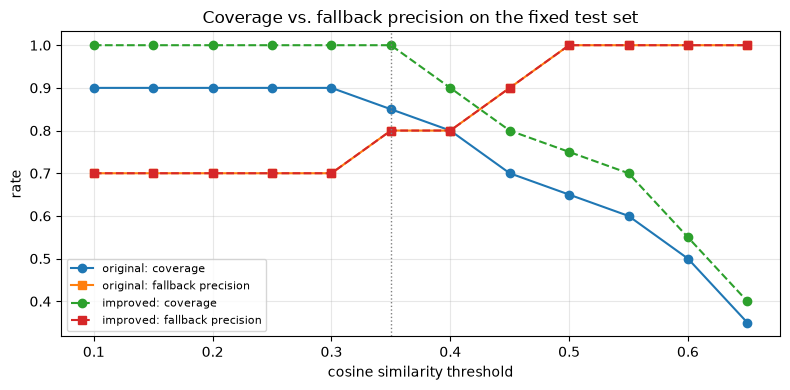

In [18]:
retrieve_stemmed, _, _ = build_retrieval_system(claims, responses, sources,
                                                remove_stopwords=True, stem=True)


def sweep_metrics(retrieve_fn, threshold):
    """Compute coverage, fallback precision and wrong answers at one threshold.

    Args:
        retrieve_fn (callable): Retriever returning the retrieve_response dict.
        threshold   (float):    Fallback threshold.

    Returns:
        tuple: (coverage_rate, fallback_precision, wrong_answers) where
               wrong_answers counts answered in-scope queries whose matched
               claim is not the expected entry.
    """
    res = run_all_queries(TEST_QUERIES, threshold, retrieve_fn=retrieve_fn)
    ins = [r for r in res if r['scope'] == 'in_scope']
    oos = [r for r in res if r['scope'] == 'out_of_scope']
    wrong = sum(1 for r, exp in zip(ins, EXPECTED_ENTRY)
                if not r['fallback'] and r['matched_claim'] != claims[exp])
    return (sum(not r['fallback'] for r in ins) / len(ins),
            sum(r['fallback'] for r in oos) / len(oos), wrong)


thresholds = np.round(np.arange(0.10, 0.651, 0.05), 2)
systems = {'original': retrieve_response, 'improved': retrieve_response_improved,
           'stemmed baseline': retrieve_stemmed}
sweep = {name: [sweep_metrics(fn, th) for th in thresholds] for name, fn in systems.items()}

print(f"{'thr':>5} | {'original cov / fb-prec / wrong':>31} | "
      f"{'improved cov / fb-prec / wrong':>31} | {'stemmed cov / fb-prec / wrong':>30}")
for k, th in enumerate(thresholds):
    row = ' | '.join(f"{c:>9.2f} / {p:>7.2f} / {w:>5d}"
                     for c, p, w in (sweep[n][k] for n in systems))
    mark = '  <- THRESHOLD' if np.isclose(th, THRESHOLD) else (
           '  <- THRESHOLD ± 0.05' if np.isclose(abs(th - THRESHOLD), 0.05) else '')
    print(f"{th:>5.2f} | {row}{mark}")

print(f"\nQueries whose result changes under stemming (threshold {THRESHOLD}):")
base_res = run_all_queries(TEST_QUERIES, THRESHOLD)
stem_res = run_all_queries(TEST_QUERIES, THRESHOLD, retrieve_fn=retrieve_stemmed)
for n, (r0, r1) in enumerate(zip(base_res, stem_res), start=1):
    if r0['matched_claim'] != r1['matched_claim']:
        print(f"  {n:>2} {r0['query'][:44]:<45} {(r0['matched_claim'] or '(fallback)')[:32]:<33}"
              f"-> {(r1['matched_claim'] or '(fallback)')[:32]}")

fig, ax = plt.subplots(figsize=(8, 4))
for name, style in [('original', '-'), ('improved', '--')]:
    ax.plot(thresholds, [m[0] for m in sweep[name]], style, marker='o', label=f'{name}: coverage')
    ax.plot(thresholds, [m[1] for m in sweep[name]], style, marker='s', label=f'{name}: fallback precision')
ax.axvline(THRESHOLD, color='grey', lw=1, ls=':')
ax.set_xlabel('cosine similarity threshold'); ax.set_ylabel('rate')
ax.set_title('Coverage vs. fallback precision on the fixed test set')
ax.legend(fontsize=8, loc='lower left'); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

### 7.4 — Adjacent-misinformation probes (for Parts 4.4 B, 5.4 and 6)

These are ten claims I wrote that sit next to bank topics without being covered by any bank entry. The right behavior for each is to fall back, because the nearest entry rebuts a different claim. Two side-effect probes then check queries where a synonym-map key (*shot*) is used in its other sense.

In [19]:
ADJACENT_PROBES = [
    "do covid shots cause infertility in women",
    "is ivermectin a proven cure for the coronavirus",
    "were the covid jabs tested on pregnant women",
    "did nasa fake the photos from the mars rover",
    "is the government putting lithium in tap water",
    "are offshore wind farms killing whales",
    "is china buying up american farmland",
    "was martin luther king assassinated by the government",
    "does 5g radiation kill birds",
    "did russia hack the 2016 election",
]
SIDE_EFFECT_PROBES = [
    "was jfk shot by the deep state",                 # covered by the JFK entry
    "were shots fired at the pizza restaurant",        # 'shots' = gunfire
]


def probe_table(probes):
    """Print nearest entries and fallback decisions for both systems.

    Args:
        probes (list[str]): Queries to test.

    Returns:
        tuple: (fallbacks under the original system, fallbacks under the
                improved system), each an int count.
    """
    fb1 = fb2 = 0
    for q in probes:
        b1, s1, _ = top_match(q, vectorizer, claim_matrix)
        b2, s2, _ = top_match(q, vectorizer_v2, claim_matrix_v2, apply_synonym_map)
        fb1 += s1 < THRESHOLD; fb2 += s2 < THRESHOLD_IMPROVED
        print(f"{q[:48]:<49} {short(b1):<35}{s1:>6.3f}{' FB' if s1 < THRESHOLD else '   '}"
              f"  | {short(b2):<35}{s2:>6.3f}{' FB' if s2 < THRESHOLD_IMPROVED else ''}")
    return fb1, fb2


print(f"{'probe':<49} {'original: nearest claim':<35}{'sim':>6}     | "
      f"{'improved: nearest claim':<35}{'sim':>6}")
print('-' * 150)
fb1, fb2 = probe_table(ADJACENT_PROBES)
print(f"\nAdjacent probes that fell back (fallback precision on adjacent claims): "
      f"original {fb1}/{len(ADJACENT_PROBES)} = {fb1/len(ADJACENT_PROBES):.2f}, "
      f"improved {fb2}/{len(ADJACENT_PROBES)} = {fb2/len(ADJACENT_PROBES):.2f}")
print("\nSide-effect probes:")
_ = probe_table(SIDE_EFFECT_PROBES)

probe                                             original: nearest claim               sim     | improved: nearest claim               sim
------------------------------------------------------------------------------------------------------------------------------------------------------
do covid shots cause infertility in women         do covid 19 vaccines cause autism   0.558     | do covid 19 vaccines cause autism   0.746
is ivermectin a proven cure for the coronavirus   can drinking bleach or taking hydr  0.420     | can drinking bleach or taking hydr  0.504
were the covid jabs tested on pregnant women      do covid 19 vaccines cause autism   0.369     | do covid 19 vaccines cause autism   0.617
did nasa fake the photos from the mars rover      is the earth flat and nasa lying a  0.471     | is the earth flat and nasa lying a  0.471
is the government putting lithium in tap water    is fluoride in drinking water a go  0.549     | is fluoride in drinking water a go  0.549
are offsh

### 7.5 — Dense retrieval with `all-MiniLM-L6-v2` (for Part 6, Q1)

The same 30 test queries and 10 adjacent probes, ranked by cosine similarity between sentence embeddings of the raw query and the raw bank claims, with no preprocessing.

In [20]:
install_if_missing('sentence_transformers', 'sentence-transformers')
from sentence_transformers import SentenceTransformer

st_model = SentenceTransformer('sentence-transformers/all-MiniLM-L6-v2',
                               device='cuda' if torch.cuda.is_available() else 'cpu')
claim_emb = st_model.encode(claims, normalize_embeddings=True)


def dense_top(queries):
    """Rank bank claims for each query by embedding cosine similarity.

    Args:
        queries (list[str]): Raw query strings.

    Returns:
        tuple: (best indices (np.ndarray[int]), best cosines (np.ndarray[float])).
    """
    q_emb = st_model.encode(queries, normalize_embeddings=True)
    sims = q_emb @ claim_emb.T
    return sims.argmax(axis=1), sims.max(axis=1)


ins_q = [q for q, _ in in_scope_queries]
oos_q = [q for q, _ in out_scope_queries]
d_idx, d_sim = dense_top(ins_q)
o_idx, o_sim = dense_top(oos_q)
a_idx, a_sim = dense_top(ADJACENT_PROBES)

print("In-scope queries (dense):")
for n, (q, b, s) in enumerate(zip(ins_q, d_idx, d_sim), start=1):
    print(f"  {n:>2} {'✓' if b == EXPECTED_ENTRY[n-1] else '✗'} {s:.3f}  {short(b)}")
print(f"\nDense nearest claim is the expected entry: "
      f"{sum(b == e for b, e in zip(d_idx, EXPECTED_ENTRY))}/20 (TF-IDF original: {top1_v1}/20)")
print(f"Dense cosine, in-scope   : min={d_sim.min():.3f}  median={np.median(d_sim):.3f}")
print(f"Dense cosine, out-of-scope: max={o_sim.max():.3f}  median={np.median(o_sim):.3f}")
print(f"Dense cosine, adjacent    : min={a_sim.min():.3f}  median={np.median(a_sim):.3f}  max={a_sim.max():.3f}")
print("\nAdjacent probes (dense):")
for q, b, s in zip(ADJACENT_PROBES, a_idx, a_sim):
    print(f"  {s:.3f}  {q[:48]:<49} -> {short(b)}")

In-scope queries (dense):
   1 ✓ 0.682  did widespread voter fraud affect 
   2 ✗ 0.557  did widespread voter fraud affect 
   3 ✓ 0.631  did mail-in voting cause large-sca
   4 ✗ 0.440  is mainstream media always lying a
   5 ✓ 0.760  did george soros fund antifa and c
   6 ✓ 0.871  do covid 19 vaccines cause autism
   7 ✓ 0.433  were covid 19 vaccines approved to
   8 ✓ 0.652  does the covid 19 vaccine contain 
   9 ✓ 0.655  did the us government create covid
  10 ✓ 0.869  can drinking bleach or taking hydr
  11 ✓ 0.690  is climate change a hoax invented 
  12 ✓ 0.726  was there a global warming pause t
  13 ✓ 0.792  do volcanoes emit more co2 than hu
  14 ✓ 0.705  do undocumented immigrants commit 
  15 ✓ 0.787  is there an immigrant invasion at 
  16 ✓ 0.757  did the us lose millions of jobs t
  17 ✓ 0.857  is the us national debt owned most
  18 ✓ 0.864  do 5g towers cause cancer or sprea
  19 ✓ 0.695  was the moon landing faked by nasa
  20 ✓ 0.909  is fluoride in drinking water 

### 7.6 — ROUGE-1 cross-check (for Part 1.4)

`compute_rouge1` follows the stub's whitespace tokenization, so punctuation stays attached to words ("election." ≠ "election"). `rouge_score` strips punctuation before counting, which explains any gap between the two.

In [21]:
from rouge_score import rouge_scorer

scorer = rouge_scorer.RougeScorer(['rouge1'], use_stemmer=False)
for name, summary in [('Extractive', extractive_summary), ('Abstractive', abstractive_summary)]:
    lib = scorer.score(reference_text, summary)['rouge1']
    own = compute_rouge1(summary, reference_text)
    print(f"{name:<12} own F1={own['f1']:.4f}   rouge_score F1={lib.fmeasure:.4f} "
          f"(P={lib.precision:.4f}, R={lib.recall:.4f})")

ext_sents = [' '.join(s.split()) for s in sent_tokenize(extractive_summary)]
print(f"\nExtractive sentences that also appear in the 100-word reference: "
      f"{sum(s in reference_text for s in ext_sents)} of {len(ext_sents)}")
print(f"Summary lengths (words): extractive {len(extractive_summary.split())}, "
      f"abstractive {len(abstractive_summary.split())}, article {len(article_text.split())}")

# Effect of the missing-space repair in textrank_summarize
raw_sents   = sent_tokenize(str(article_text))
fixed_sents = sent_tokenize(_MISSING_SPACE.sub(r'\1 \2', str(article_text)))
print(f"\nSentences found: raw text {len(raw_sents)}, after restoring missing spaces "
      f"{len(fixed_sents)}")
no_fix = compute_rouge1(' '.join(raw_sents), reference_text)   # n_sentences=3 >= 3 -> whole article
print(f"Without the repair, the 'summary' is the whole article: ROUGE-1 "
      f"P={no_fix['precision']:.4f} R={no_fix['recall']:.4f} F1={no_fix['f1']:.4f}")

# Which correction would each summary retrieve if used as the fact-checking query?
print("\nSummary used as a retrieval query (baseline system):")
for name, summary in [('Extractive', extractive_summary), ('Abstractive', abstractive_summary)]:
    b, s, terms = top_match(summary, vectorizer, claim_matrix)
    print(f"  {name:<12} -> {claims[b]} (sim {s:.3f}; {len(terms)} query terms in bank vocabulary)")
abs_words = set(re.findall(r"[a-z0-9']+", abstractive_summary.lower()))
art_words = set(re.findall(r"[a-z0-9']+", article_text.lower()))
print(f"Abstractive summary words not found anywhere in the article: "
      f"{sorted(abs_words - art_words)}")

Extractive   own F1=0.7664   rouge_score F1=0.8111 (P=0.7719, R=0.8544)
Abstractive  own F1=0.2556   rouge_score F1=0.2628 (P=0.5294, R=0.1748)

Extractive sentences that also appear in the 100-word reference: 2 of 3
Summary lengths (words): extractive 114, abstractive 33, article 309

Sentences found: raw text 3, after restoring missing spaces 10
Without the repair, the 'summary' is the whole article: ROUGE-1 P=0.3236 R=1.0000 F1=0.4890

Summary used as a retrieval query (baseline system):
  Extractive   -> was there a global warming pause that disproved climate change (sim 0.645; 14 query terms in bank vocabulary)
  Abstractive  -> was there a global warming pause that disproved climate change (sim 0.634; 4 query terms in bank vocabulary)
Abstractive summary words not found anywhere in the article: ['says', 'u']


### 7.7 — Corpus topic and format check (for Part 1.4)

This cell gives the date range of the corpus and the share of fake and real articles that mention each bank topic. It also shows how often an article has a full stop glued to the next sentence, which is the formatting problem that `textrank_summarize` repairs.

In [22]:
dates = pd.to_datetime(data['date'].astype(str).str.strip(), errors='coerce', format='mixed')
print(f"Article dates: {dates.min():%Y-%m-%d} to {dates.max():%Y-%m-%d} "
      f"({dates.isna().sum()} unparsed)")

fake_text = data.loc[data['class'] == 0, 'text'].fillna('').str.lower()
real_text = data.loc[data['class'] == 1, 'text'].fillna('').str.lower()
TOPIC_PATTERNS = {
    'covid / coronavirus':      r'covid|coronavirus',
    'vaccine':                  r'vaccin',
    'climate / global warming': r'climate|global warming',
    'muslim / islam':           r'muslim|islam',
    'immigrant / refugee':      r'immigra|refugee',
    'voter fraud / rigged':     r'voter fraud|election fraud|rigged',
    'soros':                    r'soros',
    'pizzagate':                r'pizzagate',
    'russia':                   r'russia',
}
print(f"\n{'share of articles mentioning':<30} {'fake':>6} {'real':>6}")
for name, pat in TOPIC_PATTERNS.items():
    print(f"{name:<30} {fake_text.str.contains(pat).mean():>6.3f} "
          f"{real_text.str.contains(pat).mean():>6.3f}")

glued = r'[a-z][.!?][A-Z]'
fake_raw = data.loc[data['class'] == 0, 'text'].fillna('')
real_raw = data.loc[data['class'] == 1, 'text'].fillna('')
print(f"\nArticles with a sentence glued to the next ('last.Thank'): "
      f"fake {fake_raw.str.contains(glued).mean():.3f}, real {real_raw.str.contains(glued).mean():.3f}")

Article dates: 2015-03-31 to 2018-02-19 (10 unparsed)



share of articles mentioning     fake   real
covid / coronavirus             0.000  0.000
vaccine                         0.002  0.003


climate / global warming        0.030  0.034


muslim / islam                  0.122  0.178


immigrant / refugee             0.114  0.124


voter fraud / rigged            0.019  0.010
soros                           0.015  0.001
pizzagate                       0.001  0.000


russia                          0.113  0.162



Articles with a sentence glued to the next ('last.Thank'): fake 0.892, real 0.009


---

## Submission checklist

Before uploading to Canvas:

- [x] All cells run top-to-bottom without errors (**Runtime → Run all**)
- [x] All evaluation tables filled in (Parts 4 and 5)
- [x] All reflections completed (Parts 1, 3, 4, 5, 6)
- [x] Part 2 (System Design) fully written before running Part 3
- [x] Named output variables defined:  
  `extractive_rouge_f1`, `abstractive_rouge_f1`,  
  `initial_mean_relevance`, `initial_mean_coherence`, `initial_mean_accuracy`,  
  `initial_coverage_rate`, `initial_fallback_precision`,  
  `improved_mean_relevance`, `improved_mean_coherence`, `improved_mean_accuracy`,  
  `improved_coverage_rate`, `improved_fallback_precision`
- [x] Every function has a complete docstring
- [x] File saved as `Lab_12.ipynb`